# Heart Failure Prediction
## Multiple Linear Regression (simple version)

**Question:** can we predict whether a heart-failure patient dies during the follow-up period, using medical measurements?

- **Inputs (X):** measurements such as age, ejection fraction and serum creatinine.
- **Answer (y):** `DEATH_EVENT`, where **1 = the patient died** and **0 = the patient survived**.

This is the same idea as Part A of the *regression notebook* (predict marks from hours), but now the model gets **several inputs at once**. That is called **multiple linear regression**.

The model gives every patient a **risk score**: a number that is mostly between 0 (very safe) and 1 (very risky). If the score is **0.5 or more**, we say the model predicts "died".

**The five parts**

| Part | What we do |
|---|---|
| 1. Data pre-processing | look at the data, scale it, find the useful measurements |
| 2. Training and testing sets | keep 20 % of the patients for the final check |
| 3. Training and testing the model | `fit()` to train, `predict()` to test |
| 4. Training plots | pictures of how the model fits the training patients |
| 5. Evaluation metrics | MAE, RMSE, R², accuracy, confusion matrix, precision, recall, F1 score |

> **About the code:** to keep things simple, this notebook uses only code from two notebooks: *My first Machine Learning notebook* (Linear Regression + Logistic Regression, called the **regression notebook** below) and the **pandas notebook**. The only two new words are `coef_` and `intercept_` in step 3.2, which show the weights and the bias of the model. Nothing later depends on that step.

> **Before you start:** keep `heart_failure_clinical_records_dataset.csv` in the **same folder** as this notebook. If you see `FileNotFoundError`, the file is in another folder or its name is different. (In Google Colab, upload it first with the *Files* panel.)

---
## 1. Data pre-processing

### 1.0 Import the tools

These lines give us ready-made tools (the same ones as in the regression notebook). **You do not need to memorize the imports.**

- `pandas` makes data tables.
- `matplotlib` draws graphs.
- `scikit-learn` provides the machine learning model and the scores.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, accuracy_score, confusion_matrix, precision_score, recall_score, root_mean_squared_error, f1_score

### 1.1 Meet the data

Each row is one **patient** (299 patients). The columns are measurements taken from them.

| Column | Meaning |
|---|---|
| `age` | age in years |
| `anaemia` | low red blood cells or haemoglobin (1 = yes, 0 = no) |
| `creatinine_phosphokinase` | level of the CPK enzyme in the blood |
| `diabetes` | has diabetes (1 = yes, 0 = no) |
| `ejection_fraction` | % of blood the heart pumps out with each beat |
| `high_blood_pressure` | has high blood pressure (1 = yes, 0 = no) |
| `platelets` | platelets in the blood |
| `serum_creatinine` | creatinine level in the blood (kidney health) |
| `serum_sodium` | sodium level in the blood |
| `sex` | woman or man (0 or 1) |
| `smoking` | smokes (1 = yes, 0 = no) |
| `time` | follow-up time in days |
| `DEATH_EVENT` | **the answer**: 1 = died, 0 = survived |

`pd.read_csv()` reads the file into a table. The file name is **relative**, so it works on any computer as long as the CSV is in the same folder as this notebook.

In [3]:
df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


### 1.2 Check the data

Before using data, always check it:

- `info()` shows the type of each column. Here every column is already a number, so nothing needs converting.
- `isnull().sum()` counts the **missing values** in each column. We want zeros, so we do not need `dropna()` or `fillna()`.
- `describe()` shows the average (`mean`), the spread (`std`), the smallest (`min`) and the largest (`max`) value of each column.

We also count how many patients died. **About one third** died, so "survived" is the more common answer. Remember this for later: a model that always says "survived" would already be right about 68 % of the time.

In [4]:
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nPatients who died:    ", df["DEATH_EVENT"].sum())
print("Patients who survived:", len(df) - df["DEATH_EVENT"].sum())

display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB

Missing values in

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


### 1.3 Draw the data

A **scatter plot** shows one dot for each patient. We use two measurements, **follow-up time** and **ejection fraction**, and colour each dot by what happened: **yellow = died, purple = survived**. The colours come from the number in `DEATH_EVENT`, like the flowers in Part B of the regression notebook.

**What to notice:** the yellow dots (patients who died) are mostly on the **left**, where the follow-up time is short. Patients who were followed for a long time are mostly purple.

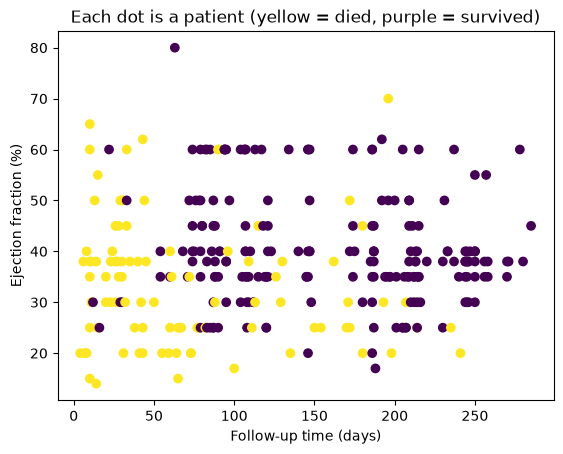

In [5]:
plt.scatter(df["time"], df["ejection_fraction"], c=df["DEATH_EVENT"])
plt.xlabel("Follow-up time (days)")
plt.ylabel("Ejection fraction (%)")
plt.title("Each dot is a patient (yellow = died, purple = survived)")
plt.show()

### 1.4 Normalization: put every column on the same scale

Look at the `describe()` table above. `platelets` is around **260,000**, but `anaemia` is only **0 or 1**. Columns on such different scales are hard to compare: a weight on `platelets` and a weight on `anaemia` would be in completely different units.

**Normalization** rewrites every value as *"how many std away from the average is it?"*

> new value = (value − average) / std

After this, every column has **average 0 and std 1**. A value of +1 means "one std above the average patient", and −1 means "one std below".

Good news: `describe()` already worked out the average (`mean`) and the `std` of every column. We pick those two rows with `loc` and reuse them.

We scale the 12 **input** columns only. The answer column (`DEATH_EVENT`) stays 0/1.

> **Note:** to keep things simple, the average and std come from **all** patients. For plain linear regression this does **not** change the predictions; it only makes the weights easy to compare.

In [6]:
all_features = ["age", "anaemia", "creatinine_phosphokinase", "diabetes", "ejection_fraction",
                "high_blood_pressure", "platelets", "serum_creatinine", "serum_sodium",
                "sex", "smoking", "time"]

X_all = df[all_features]                       # the 12 input columns (notice the double brackets)

stats = X_all.describe()                       # describe() gives the mean and the std of every column
X_scaled = (X_all - stats.loc["mean"]) / stats.loc["std"]

print("After scaling, every column has mean 0 and std 1:")
display(X_scaled.describe().round(2) + 0.0)    # "+ 0.0" only removes a harmless "-0.00"

After scaling, every column has mean 0 and std 1:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
count,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00
mean,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.75,-0.87,-0.58,-0.85,-2.03,-0.73,-2.44,-0.86,-5.35,-1.36,-0.69,-1.63
25%,-0.83,-0.87,-0.48,-0.85,-0.68,-0.73,-0.52,-0.48,-0.59,-1.36,-0.69,-0.74
50%,-0.07,-0.87,-0.34,-0.85,-0.01,-0.73,-0.01,-0.28,0.08,0.73,-0.69,-0.20
75%,0.77,1.15,0.00,1.18,0.58,1.36,0.41,0.01,0.76,0.73,1.45,0.94
max,2.87,1.15,7.50,1.18,3.54,1.36,6.00,7.74,2.58,0.73,1.45,1.99


### 1.5 Correlation: which measurements go with death?

A measurement is **useful** if it is *different* for patients who died and patients who survived. So we:

1. split the scaled table into patients who **died** and patients who **survived** (filtering, like `df[df["Python"]>80]` in the pandas notebook),
2. take the **average** of every measurement in each group (`mean()`),
3. subtract: **gap = average of died − average of survived**.

A big gap (positive or negative) means the two groups are different, so the measurement helps. A gap close to 0 means it tells us very little.

The gap is closely related to **correlation**, the number between −1 and +1 that says how strongly two things move together. For a yes/no answer such as `DEATH_EVENT`:

> correlation ≈ gap × √(p × (1 − p)), where p is the share of patients who died (about 0.32, so the factor is about **0.47**)

So the last column of the table is the (approximate) **correlation of each measurement with death**: **+** means a higher value goes with a higher risk, **−** means a higher value goes with a lower risk. (If you later learn `df.corr()`, you will get almost exactly the same numbers.)

In [7]:
died = X_scaled[df["DEATH_EVENT"] == 1]            # scaled rows of the patients who died
survived = X_scaled[df["DEATH_EVENT"] == 0]        # scaled rows of the patients who survived

p = df["DEATH_EVENT"].mean()                       # share of patients who died
factor = (p * (1 - p)) ** 0.5                      # about 0.47

gap_table = pd.DataFrame({
    "survived (average)": survived.mean(),
    "died (average)": died.mean(),
    "gap": died.mean() - survived.mean(),
})
gap_table["correlation (approx.)"] = gap_table["gap"] * factor

print("Share of patients who died:", round(p, 2), "  factor:", round(factor, 2))
display(gap_table.round(2))

Share of patients who died: 0.32   factor: 0.47


,survived (average),died (average),gap,correlation (approx.)
age,-0.17,0.37,0.54,0.25
anaemia,-0.05,0.10,0.14,0.07
creatinine_phosphokinase,-0.04,0.09,0.13,0.06
diabetes,0.00,-0.00,-0.00,-0.00
ejection_fraction,0.18,-0.39,-0.57,-0.27
high_blood_pressure,-0.05,0.12,0.17,0.08
platelets,0.03,-0.07,-0.11,-0.05
serum_creatinine,-0.20,0.43,0.63,0.29
serum_sodium,0.13,-0.28,-0.42,-0.19
sex,0.00,-0.01,-0.01,-0.00


### 1.6 Feature selection: choose the inputs

Not every measurement helps. Using only the helpful ones makes the model **simpler** and less likely to learn noise.

**Our rule:** keep a measurement if its correlation with death is at least **0.10** in size, in either direction (`>= cutoff` or `<= -cutoff`, where `|` means "or" as in the pandas notebook).

**What to notice:** five measurements pass: `age`, `ejection_fraction`, `serum_creatinine`, `serum_sodium` and `time`. By far the biggest is `time`. The others (`anaemia`, `diabetes`, `sex`, `smoking`, ...) are almost the same for patients who died and survived, so we drop them.

The `features` list is the **one place** that decides which measurements the model uses. The other scaled columns stay in `X_scaled`, so we can still draw them in plots later.

**TRY IT:** change `cutoff` from `0.10` to `0.03` and run the cell again. Four more measurements get in. Then edit the `features` list to match.

> We looked at all patients to choose the features. For this simple notebook that is fine; a stricter approach would use only the training patients.

In [8]:
cutoff = 0.10                                     # TRY IT: change to 0.03

r = gap_table["correlation (approx.)"]
big = gap_table[(r >= cutoff) | (r <= -cutoff)]   # keep the correlations that are at least this big (+ or -)
display(big.round(2))

features = ["age", "ejection_fraction", "serum_creatinine", "serum_sodium", "time"]    # the names in the table above

y = df["DEATH_EVENT"]                             # answer: 1 = died, 0 = survived
print("Inputs we will use:", features)

,survived (average),died (average),gap,correlation (approx.)
age,-0.17,0.37,0.54,0.25
ejection_fraction,0.18,-0.39,-0.57,-0.27
serum_creatinine,-0.20,0.43,0.63,0.29
serum_sodium,0.13,-0.28,-0.42,-0.19
time,0.36,-0.77,-1.13,-0.53


Inputs we will use: ['age', 'ejection_fraction', 'serum_creatinine', 'serum_sodium', 'time']


---
## 2. Training and testing sets

### 2.1 Keep some patients for testing

We must not give the model all the answers while it learns.

- **Training set:** patients used to learn.
- **Test set:** patients kept aside to check the predictions at the end.

We use **80 % for training and 20 % for testing**. With 299 patients, that is 239 and 60.

- `random_state=42` makes the random split the same every time.
- `stratify=y` keeps the share of patients who died the same in both sets (as in Part B of the regression notebook).

We split **all 12 scaled columns** (`X_scaled`), not only the five chosen ones. The model will pick its five columns later with `X_train[features]`. This way every column is still there for the plots, and you can change the `features` list whenever you like.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)

print("Training patients:", len(X_train))
print("Testing patients: ", len(X_test))
print("Share who died, training set:", round(y_train.mean(), 2))
print("Share who died, testing set: ", round(y_test.mean(), 2))

Training patients: 239
Testing patients:  60
Share who died, training set: 0.32
Share who died, testing set:  0.32


---
## 3. Training and testing the model

We do not need to write long training and testing functions, because scikit-learn already has them (the same ones as in the regression notebook):

| Function | What it does |
|---|---|
| `LinearRegression()` | creates an empty model |
| `fit(inputs, answers)` | **training**: the model learns from the training patients |
| `predict(inputs)` | **testing**: the model gives a risk score to every patient in `inputs` |

The pattern never changes: **choose inputs → split → fit → predict**.

### 3.1 Train the model

`fit()` looks at the 239 training patients (their five chosen scaled measurements, `X_train[features]`, and their real answers) and finds the best **weight** for every measurement, plus one starting number called the **bias**. The rule it learns is:

> risk score = bias + weight₁ × age + weight₂ × ejection_fraction + weight₃ × serum_creatinine + weight₄ × serum_sodium + weight₅ × time

"Best" means: the weights that make the risk scores as close as possible to the real answers (0 or 1) of the training patients.

In [10]:
model = LinearRegression()
model.fit(X_train[features], y_train)

print("The model has learned from", len(X_train), "patients and", len(features), "measurements.")

The model has learned from 239 patients and 5 measurements.


### 3.2 Look inside the model: weights and bias

This is the only cell with two words that are **not** in the two notebooks: `intercept_` (the **bias**) and `coef_` (the **weights**). Nothing later depends on this cell.

- The **bias** is the risk score of an **average patient** (every scaled measurement = 0).
- A **weight** says how much the risk score changes when that measurement goes **up by one std** and the others stay the same. **+** raises the risk, **−** lowers it.

**What to notice** (in our run): `time` has the biggest weight, about −0.22, so a longer follow-up goes with a lower risk (one std of `time` is about 78 days). Next is `ejection_fraction`, about −0.12: a heart that pumps out more blood goes with a lower risk. `serum_creatinine` (about +0.10) and `age` (about +0.05) push the risk up. `serum_sodium` is close to 0, so it hardly matters once the other four are known.

In [23]:
print("Bias:", round(model.intercept_, 4))

weights = pd.DataFrame({"measurement": features, "weight": model.coef_})
print("\nWeights: ")
display(weights.round(4))

Bias: 0.3105

Weights: 


,measurement,weight
0,age,0.0459
1,ejection_fraction,-0.1200
2,serum_creatinine,0.0962
3,serum_sodium,-0.0148
4,time,-0.2201


### 3.3 Test the model: risk scores

`predict()` applies the learned rule to patients and returns one **risk score** for each of them. We do this for the training patients and for the testing patients. The testing patients were never used for learning, so their scores show how the model behaves on **new patients**.

A higher score means a higher risk. Linear regression does not know that the real answer is only 0 or 1, so a score can be **below 0 or above 1**. That is normal, but it also means the scores are not real probabilities (logistic regression, Part B of the regression notebook, fixes this).

In [12]:
train_risk = model.predict(X_train[features])
test_risk = model.predict(X_test[features])

print("First 10 testing risk scores:", test_risk[:10].round(2))
print("Lowest and highest training risk score:", round(train_risk.min(), 2), "and", round(train_risk.max(), 2))

First 10 testing risk scores: [ 0.03  0.34  0.2   0.23  0.21 -0.22  0.06  0.29 -0.13  0.37]
Lowest and highest training risk score: -0.45 and 1.51


### 3.4 From risk score to answer: the 0.5 rule

We need a yes/no answer: died (1) or survived (0). Our rule is **risk score ≥ 0.5 → predict "died" (1)**, otherwise "survived" (0). The number 0.5 is called the **threshold**.

In the code, `test_risk >= threshold` gives True or False for every patient, and multiplying by 1 turns True into 1 and False into 0.

The table shows the first 10 testing patients: the risk score, the model's answer and the real answer.

**TRY IT:** change `threshold` to 0.3. More patients will be called "died". Run the cells below again and see what happens to recall and precision in step 5.4.

In [13]:
threshold = 0.5

train_died = (train_risk >= threshold) * 1
test_died = (test_risk >= threshold) * 1

compare = pd.DataFrame({
    "risk score": test_risk,
    "predicted answer": test_died,
    "actual answer": y_test.to_numpy(),
})
display(compare.head(10).round(2))

,risk score,predicted answer,actual answer
0,0.03,0,0
1,0.34,0,0
2,0.20,0,0
3,0.23,0,0
4,0.21,0,0
5,-0.22,0,0
6,0.06,0,0
7,0.29,0,1
8,-0.13,0,0
9,0.37,0,0


---
## 4. Training plots

Two pictures show how the trained model sees the **training patients**. In both pictures every dot is one patient.

### 4.1 Risk score and follow-up time

- **x-axis:** follow-up time (scaled, so 0 = average, −1 = shorter than average, +1 = longer than average).
- **y-axis:** the risk score from the model.
- **colour:** what really happened (yellow = died, purple = survived), as in step 1.3.
- **black line:** the threshold (0.5). Dots above the line are predicted "died", dots below it are predicted "survived".

**What to notice:**
1. The dots slope **downwards** to the right: the longer the follow-up, the lower the risk score (the weight of `time` is negative).
2. Most yellow dots are above the line and most purple dots are below it, so the model separates the two groups fairly well.
3. Dots on the "wrong" side of the line are the model's mistakes. Some scores are below 0 or above 1.

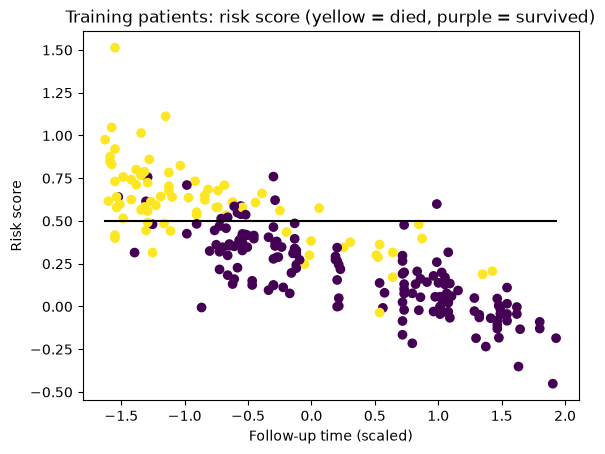

In [14]:
plt.scatter(X_train["time"], train_risk, c=y_train)
plt.plot([X_train["time"].min(), X_train["time"].max()], [threshold, threshold], c="black")
plt.xlabel("Follow-up time (scaled)")
plt.ylabel("Risk score")
plt.title("Training patients: risk score (yellow = died, purple = survived)")
plt.show()

### 4.2 A map of the risk scores

Now both axes are measurements: **follow-up time** (x) and **ejection fraction** (y), the two biggest weights in step 3.2. This time the colour is the **model's risk score** (yellow = high risk, purple = low risk), not what really happened.

**What to notice:** compare this picture with the one in step 1.3, where the colours showed what really happened. The model's high-risk dots (yellow-green) are at the **left and lower part**: short follow-up and low ejection fraction, which is where most of the real deaths were. The lowest-risk dots (dark purple) are at the **right and upper part**. So the model has learned a pattern that is really in the data.

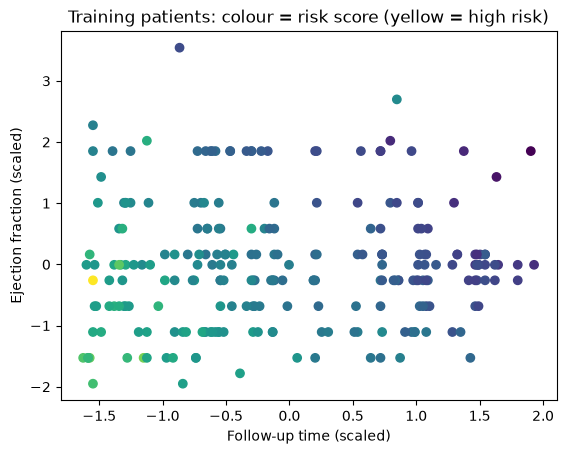

In [15]:
plt.scatter(X_train["time"], X_train["ejection_fraction"], c=train_risk)
plt.xlabel("Follow-up time (scaled)")
plt.ylabel("Ejection fraction (scaled)")
plt.title("Training patients: colour = risk score (yellow = high risk)")
plt.show()

---
## 5. Evaluation metrics

Now we check the model with numbers. The most important numbers are the ones for the **testing patients**, because the model has never seen them. The training numbers are shown next to them for comparison.

### 5.1 How far are the risk scores from the real answers? (MAE, RMSE, R²)

These three scores treat the risk score as a number and measure how far it is from the real answer (0 or 1).

- **MAE** (Mean Absolute Error): the average size of the miss. Smaller is better. (Same as in the regression notebook.)
- **RMSE** (Root Mean Squared Error): square every miss, take the average, then take the square root. Big misses count more than small ones. Smaller is better, and it is never smaller than MAE.
- **R²**: how much better the model is than the simplest guess, "everybody gets the average risk". **1 = perfect, 0 = no better than that guess**, below 0 = worse.

The code uses only `mean()`, `sum()`, `** 2` (square) and `** 0.5` (square root).

**What to notice** (in our run): the testing scores are not far from the training scores, so the model is not just memorising the training patients. R² on the testing patients is a little above one third: the five measurements explain part of the answer, but far from all of it. That is normal for a simple linear model with a yes/no answer.

In [16]:
mae_train = mean_absolute_error(y_train, train_risk)
mae_test = mean_absolute_error(y_test, test_risk)

rmse_train = root_mean_squared_error(y_train, train_risk)
rmse_test = root_mean_squared_error(y_test, test_risk)

r2_train = 1 - ((y_train - train_risk) ** 2).sum() / ((y_train - y_train.mean()) ** 2).sum()
r2_test = 1 - ((y_test - test_risk) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum()

scores = pd.DataFrame({
    "score": ["MAE", "RMSE", "R2"],
    "training": [mae_train, rmse_train, r2_train],
    "testing": [mae_test, rmse_test, r2_test],
})
display(scores.round(3))

,score,training,testing
0,MAE,0.292,0.290
1,RMSE,0.358,0.371
2,R2,0.414,0.363


### 5.2 Accuracy

**Accuracy** is the fraction of patients for which the yes/no answer is correct (as in Part B of the regression notebook).

We compare it with a very lazy model that **always says "survived"**. About 68 % of the patients survived, so the lazy model is already right about 68 % of the time. **Our model must beat that to be worth anything.** In the code, `y_test.mean()` is the share of testing patients who died, so `1 - y_test.mean()` is the lazy model's accuracy.

In [17]:
train_accuracy = accuracy_score(y_train, train_died)
test_accuracy = accuracy_score(y_test, test_died)
lazy_accuracy = 1 - y_test.mean()

print("Accuracy on training patients:", round(train_accuracy, 3))
print("Accuracy on testing patients: ", round(test_accuracy, 3))
print("Always saying 'survived':     ", round(lazy_accuracy, 3))

Accuracy on training patients: 0.845
Accuracy on testing patients:  0.833
Always saying 'survived':      0.683


### 5.3 Confusion matrix

Accuracy hides *which* mistakes are made. The **confusion matrix** counts them. Rows are the actual answers and columns are the predicted answers (as in the regression notebook):

```text
                        Predicted survived (0)    Predicted died (1)
Actual survived (0)     TN  true negative         FP  false alarm
Actual died (1)         FN  missed death          TP  true positive
```

- **TP** (true positive): the patient died and the model said "died".
- **TN** (true negative): the patient survived and the model said "survived".
- **FP** (false positive): the patient survived but the model said "died" (a false alarm).
- **FN** (false negative): the patient died but the model said "survived" (a **missed death**, the most worrying mistake in medicine).

The numbers on the diagonal (TN and TP) are the correct predictions. We also keep the four counts in variables, because the next step needs them.

In [18]:
cm = confusion_matrix(y_test, test_died)
print(cm)

tn, fp = cm[0, 0], cm[0, 1]      # actual survived: predicted survived, predicted died
fn, tp = cm[1, 0], cm[1, 1]      # actual died:     predicted survived, predicted died

cm_table = pd.DataFrame({
    "actual answer": ["survived (0)", "died (1)"],
    "predicted survived (0)": [tn, fn],
    "predicted died (1)": [fp, tp],
})
display(cm_table)

[[39  2]
 [ 8 11]]


,actual answer,predicted survived (0),predicted died (1)
0,survived (0),39,2
1,died (1),8,11


### 5.4 Precision, Recall and F1 score

These three scores look only at the patients the model calls "died":

- **Precision** = TP / (TP + FP): *when the model says "died", how often is it right?*
- **Recall** = TP / (TP + FN): *of all the patients who really died, how many did the model find?*
- **F1 score** = 2 × precision × recall / (precision + recall): *one number that mixes the two.* It is high only when both are high.

All three are between 0 and 1. Higher is better.

**What to notice** (in our run): precision is high (when the model says "died", it is usually right) but recall is lower (the model misses a good share of the real deaths). So the model is **careful but not sensitive**. In a hospital a missed death is usually worse than a false alarm, so a good next step is to lower the threshold.

**TRY IT:** go back to step 3.4, set `threshold = 0.3` and run all the cells below it again. Recall goes up (fewer missed deaths) and precision goes down (more false alarms). In our run, recall went from 0.58 to 0.74 and precision from 0.85 to 0.54. Which one matters more for a hospital?

In [19]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

print("Precision:", round(precision, 3))
print("Recall:   ", round(recall, 3))
print("F1 score: ", round(f1, 3))

Precision: 0.846
Recall:    0.579
F1 score:  0.688


### 5.5 Testing plot

The same picture as in step 4.1, but for the **testing patients** (the model has never seen them). The mistakes are easy to spot:

- a **yellow dot below the black line** is a missed death (FN),
- a **purple dot above the black line** is a false alarm (FP).

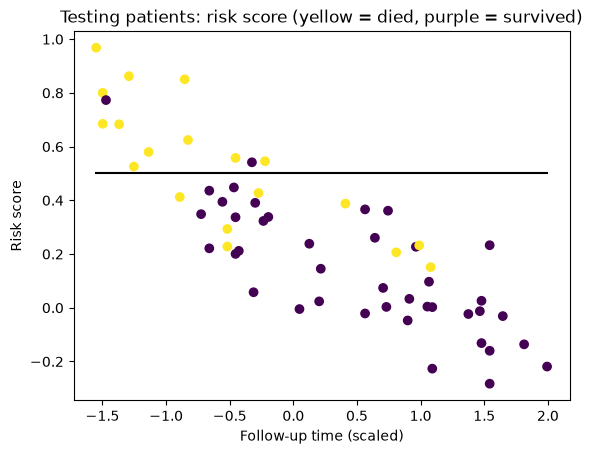

In [20]:
plt.scatter(X_test["time"], test_risk, c=y_test)
plt.plot([X_test["time"].min(), X_test["time"].max()], [threshold, threshold], c="black")
plt.xlabel("Follow-up time (scaled)")
plt.ylabel("Risk score")
plt.title("Testing patients: risk score (yellow = died, purple = survived)")
plt.show()

### 5.6 A caution about `time`

`time` is by far the strongest input, but be careful with it. It is the **length of the follow-up**, and the follow-up of a patient who dies **ends at the death**. So the patients who died have a short `time` almost by definition, and a model that uses `time` is partly using the answer to predict the answer. Also, a **new** patient who has just arrived at the hospital does not have a `time` yet.

The two numbers below show the problem.

**TRY IT (the most useful experiment in this notebook):** in step 1.6, delete `"time"` from the `features` list and run **all** the cells again. In our run the model got clearly worse: test R² fell from about 0.36 to about 0.24, accuracy from about 0.83 to 0.75, and recall from about 0.58 to 0.37. That is a more honest picture of how well the *other* measurements can predict death.

In [21]:
died_time = df[df["DEATH_EVENT"] == 1]["time"].mean()
survived_time = df[df["DEATH_EVENT"] == 0]["time"].mean()

print("Average follow-up of patients who died:    ", round(died_time, 1), "days")
print("Average follow-up of patients who survived:", round(survived_time, 1), "days")

Average follow-up of patients who died:     70.9 days
Average follow-up of patients who survived: 158.3 days


---
## Summary

**What we did**

1. **Pre-processing:** checked the data (299 patients, no missing values), scaled the 12 measurements, used the died-versus-survived gap (about the same as correlation) to keep the 5 useful ones.
2. **Split:** 80 % of the patients for training (239) and 20 % for testing (60).
3. **Model:** `LinearRegression()`, then `fit()` to train and `predict()` to test. A risk score of 0.5 or more means "died".
4. **Plots:** risk score against follow-up time, and a map of the risk scores.
5. **Metrics:** MAE, RMSE, R², accuracy, confusion matrix, precision, recall and F1 score.

**What we learned**

- The model beats the lazy "always survived" guess, and it behaves almost the same on training and testing patients.
- It still misses a good share of the real deaths (recall is low). For a medical tool we would lower the threshold.
- 60 testing patients (only 19 of whom died) is a small test set, so the numbers can change a lot with another split.
- `time` does most of the work, but it would not be known for a new patient (step 5.6).
- Linear regression gives scores outside 0 to 1. **Next step:** logistic regression (Part B of the regression notebook) gives real probabilities and is the usual model for a yes/no answer like this one.